In [35]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import math
import torch.nn.functional as F
from torch.utils.data import Subset
import numpy as np
import pandas as pd
import copy
from torch.utils.data import ConcatDataset
from IPython.display import clear_output

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import math
import torch.nn.functional as F
from torch.utils.data import Subset
import numpy as np
import pandas as pd
import copy
from torch.utils.data import ConcatDataset
from torchvision.datasets import ImageFolder
from torchvision import transforms
from torch.utils.data import DataLoader
import os
from IPython.display import clear_output

from tqdm.notebook import tqdm

In [36]:
img_size = 28

transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

batch_size = 128
train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)

In [37]:
# Assuming alpha_bar is already defined as:
# beta = torch.linspace(1e-4, 0.02, 500).to("cuda")
# alpha = 1. - beta
# alpha_bar = torch.cumprod(alpha, dim=0)

for epoch in tqdm(range(2), desc="Total Epochs"):
    # --- Training Phase ---
    encoder.train()
    classifier_head.train()
    pbar = tqdm(loader, desc=f"Epoch {epoch} Training", leave=False)
    
    for imgs, labels in pbar:
        imgs, labels = imgs.to("cuda"), labels.to("cuda")
        B = imgs.shape[0]
        
        # --- RANDOMLY NOISE THE INPUTS ---
        # Pick random timesteps for each image in the batch
        t = torch.randint(0, 500, (B,), device="cuda").long()
        noise = torch.randn_like(imgs)
        
        # Grab the corresponding alpha_bar values
        a_bar = alpha_bar[t].view(-1, 1, 1, 1)
        
        # Forward diffusion process: x_t = sqrt(alpha_bar)*x_0 + sqrt(1-alpha_bar)*epsilon
        noised_imgs = torch.sqrt(a_bar) * imgs + torch.sqrt(1 - a_bar) * noise
        
        # --- TRAIN ON NOISED DATA ---
        features = encoder(noised_imgs)
        logits = classifier_head(features)
        loss = criterion(logits, labels)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        pbar.set_postfix(loss=f"{loss.item():.4f}")

    # --- Testing Phase ---
    encoder.eval()
    classifier_head.eval()
    correct, total = 0, 0
    
    with torch.no_grad():
        for imgs, labels in tqdm(test_loader, desc="Testing", leave=False):
            imgs, labels = imgs.to("cuda"), labels.to("cuda")
            
            # Note: We test on clean images to check fundamental accuracy,
            # but you could also noise these to check "Noised Accuracy".
            features = encoder(imgs)
            logits = classifier_head(features)
            
            _, predicted = torch.max(logits.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    print(f"Epoch {epoch} | Clean Test Accuracy: {accuracy:.2f}%")

Total Epochs:   0%|          | 0/2 [00:00<?, ?it/s]

NameError: name 'encoder' is not defined

In [11]:
# 1. Prepare Data: Numerator (8s) and Denominator (All)
all_imgs = next(iter(DataLoader(train_dataset, batch_size=2000, shuffle=True)))[0].to("cuda")
is_eight = (train_dataset.targets == 4).nonzero(as_tuple=True)[0]
eight_imgs = train_dataset.data[is_eight[:1000]].unsqueeze(1).float().to("cuda") / 255.0

# 2. Extract Latent Features (X)
with torch.no_grad():
    phi_all = encoder(all_imgs)    # Features of the background distribution (De)
    phi_eight = encoder(eight_imgs) # Features of the target distribution (Nu)

# 3. Analytical Solution: theta = H^-1 * h
# H = (1/n_de) * sum(phi_all * phi_all^T) + lambda * I
# h = (1/n_nu) * sum(phi_eight)

n_de = phi_all.shape[0]
n_nu = phi_eight.shape[0]
reg = 0.1 # Regularization parameter lambda

# Calculate H (64x64 matrix)
H = (phi_all.T @ phi_all) / n_de
H += reg * torch.eye(64).to("cuda")

# Calculate h (64x1 vector)
h = torch.mean(phi_eight, dim=0, keepdim=True).T

# Solve for theta (The "1-Shot" moment)
theta = torch.linalg.solve(H, h)

print("Analytical weights theta calculated!")

All imgs: torch.Size([2000, 1, 28, 28])
Target imgs: torch.Size([190, 1, 28, 28])
PCA fitted!
Feature shapes: torch.Size([2000, 64]) torch.Size([190, 64])
Analytical theta solved!
Theta shape: torch.Size([64, 1])


In [12]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

device = "cuda"

# -------------------------------------------------
# 1️⃣ DATASET
# -------------------------------------------------

img_size = 28

transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

train_loader = DataLoader(train_dataset, batch_size=2000, shuffle=True)

# -------------------------------------------------
# 2️⃣ LOAD DATA BATCHES
# -------------------------------------------------

all_imgs, all_labels = next(iter(train_loader))
all_imgs = all_imgs.to(device)
all_labels = all_labels.to(device)

# Select target class (change if you want)
target_class = 4

mask = (all_labels == target_class)
target_imgs = all_imgs[mask][:1000]

print("All imgs:", all_imgs.shape)
print("Target imgs:", target_imgs.shape)

assert target_imgs.shape[0] > 0, "No target samples found!"

# -------------------------------------------------
# 3️⃣ FIT PCA (ONE SHOT)
# -------------------------------------------------

# Flatten images
X_all = all_imgs.view(all_imgs.shape[0], -1)

# Center
mean_vec = X_all.mean(dim=0, keepdim=True)
X_centered = X_all - mean_vec

# SVD PCA
U, S, Vt = torch.linalg.svd(X_centered, full_matrices=False)

# Number of PCA features
k = 64

W_pca = Vt[:k].T.contiguous()  # [D, k]

print("PCA fitted!")

# -------------------------------------------------
# 4️⃣ PCA ENCODER FUNCTION
# -------------------------------------------------

def pca_encode(imgs):
    X = imgs.view(imgs.shape[0], -1)
    X = X - mean_vec
    return X @ W_pca

# -------------------------------------------------
# 5️⃣ EXTRACT FEATURES
# -------------------------------------------------

with torch.no_grad():
    phi_all = pca_encode(all_imgs)
    phi_target = pca_encode(target_imgs)

print("Feature shapes:", phi_all.shape, phi_target.shape)

# -------------------------------------------------
# 6️⃣ ANALYTICAL MOMENT SOLVE
# -------------------------------------------------

n_de = phi_all.shape[0]
n_nu = phi_target.shape[0]

reg = 0.1

H = (phi_all.T @ phi_all) / n_de
H += reg * torch.eye(k, device=device)

h = phi_target.mean(dim=0, keepdim=True).T

theta = torch.linalg.solve(H, h)

print("Analytical theta solved!")
print("Theta shape:", theta.shape)


All imgs: torch.Size([2000, 1, 28, 28])
Target imgs: torch.Size([204, 1, 28, 28])
PCA fitted!
Feature shapes: torch.Size([2000, 64]) torch.Size([204, 64])
Analytical theta solved!
Theta shape: torch.Size([64, 1])


In [13]:
class BinaryClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=3, padding=1),
            nn.GroupNorm(32, 64), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.GroupNorm(32, 128), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.GroupNorm(32, 256), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.GroupNorm(32, 512), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten()
        )
        
        self.time_mlp = nn.Sequential(
            nn.Linear(1, 128),
            nn.ReLU(),
            nn.Linear(128, 128)
        )
        
        self.fc = nn.Linear(512 + 128, 2)

    def forward(self, x, t):
        img_feats = self.features(x)
        
        if t.dim() == 1:
            t = t.unsqueeze(-1).float()
            
        time_feats = self.time_mlp(t)
        
        combined = torch.cat([img_feats, time_feats], dim=1)
        return self.fc(combined)


class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels, groups=8):
        super().__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(groups, out_channels),  # GroupNorm is standard for Diffusion
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(groups, out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.double_conv(x)

class uNet(nn.Module):
    def __init__(self, time_dim=128):
        super().__init__()
        self.time_mlp = nn.Sequential(
            nn.Linear(1, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim)
        )

        self.input = DoubleConv(1, 64)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64, 128))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(128, 256))

        self.bottleneck = DoubleConv(256, 512)

        self.up1 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.conv_up1 = DoubleConv(384, 256)
        
        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.conv_up2 = DoubleConv(192, 128)

        self.output = nn.Conv2d(128, 1, kernel_size=1)

        self.emb_down1 = nn.Linear(time_dim, 128)
        self.emb_down2 = nn.Linear(time_dim, 256)
        self.emb_up1 = nn.Linear(time_dim, 256)
        self.emb_up2 = nn.Linear(time_dim, 128)

    def forward(self, x, t):
        t = t.view(-1, 1) 
        emb = self.time_mlp(t)
        
        x1 = self.input(x)
        
        x2 = self.down1(x1)
        x2 = x2 + self.emb_down1(emb)[:, :, None, None]
        
        x3 = self.down2(x2)
        x3 = x3 + self.emb_down2(emb)[:, :, None, None]

        x_mid = self.bottleneck(x3)

        x_up1 = self.up1(x_mid)
        x_up1 = torch.cat([x_up1, x2], dim=1)
        x_up1 = self.conv_up1(x_up1) 
        x_up1 = x_up1 + self.emb_up1(emb)[:, :, None, None]
        
        x_up2 = self.up2(x_up1)
        x_up2 = torch.cat([x_up2, x1], dim=1)
        x_up2 = self.conv_up2(x_up2)
        x_up2 = x_up2 + self.emb_up2(emb)[:, :, None, None]

        return self.output(x_up2)

class Classifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 64, 3, padding=1),
            nn.GroupNorm(16, 64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.1),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.GroupNorm(16, 128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.2),

            nn.Conv2d(128, 256, 3, padding=1),
            nn.GroupNorm(16, 256),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.3),

            nn.AdaptiveAvgPool2d(1),
            nn.Flatten()
        )

        self.fc = nn.Linear(256, 10)

    def forward(self, x):
        x = self.features(x)
        return self.fc(x)

In [14]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
biCls = BinaryClassifier().to(device)
cls = Classifier().to(device)
model = uNet().to(device)

biCls.load_state_dict(torch.load("8_binary_clsf.pth", map_location=device))
cls.load_state_dict(torch.load("mnist_cnn_wei.pth", map_location=device))
model.load_state_dict(torch.load("uncond_diff_wei.pth", map_location=device))

<All keys matched successfully>

In [15]:
img_size = 28
batch_size = 128
epochs = 100
timesteps = 500
img_size = 28

beta = torch.linspace(1e-4, 0.02, timesteps).to(device)
alpha = 1. - beta
alpha_bar = torch.cumprod(alpha, dim=0)

In [31]:
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

# ... (Previous code: model, encoder, theta, alpha, beta setup) ...

n_samples = 50
s = 100.0  # Set scale > 0 to see the guidance effect
img_size = 28
device = "cuda"

# Start with random noise
xt = torch.randn(n_samples, 1, img_size, img_size).to(device)

for i in reversed(range(timesteps)):
    t = torch.tensor([i] * n_samples, device=device)
    t_float = t.float() / timesteps
    
    # 1. Unconditional prediction (no grad needed)
    with torch.no_grad():
        eps_pred = model(xt, t_float)
    
    alpha_t = alpha[i]
    alpha_bar_t = alpha_bar[i]
    beta_t = beta[i]

    # Standard Diffusion Mean
    mean = (xt - ((1 - alpha_t) / torch.sqrt(1 - alpha_bar_t)) * eps_pred) / torch.sqrt(alpha_t)

    # 2. uLSIF Guidance (Requires Grad)
    # Use a clone that tracks gradients
    xt_for_grad = xt.detach().requires_grad_(True)
    
    features = encoder(xt_for_grad)
    ratio = features @ theta
    log_r = torch.log(torch.clamp(ratio, min=1e-8))
    
    # Calculate gradient of log-ratio w.r.t xt
    guide_score = torch.autograd.grad(log_r.sum(), xt_for_grad)[0]
    
    # Update mean with guidance
    mean = mean + s * beta_t * guide_score
    
    # 3. Step to next xt-1
    if i > 0:
        noise = torch.randn_like(xt)
        xt = mean + torch.sqrt(beta_t) * noise
    else:
        xt = mean

    if i % 20 == 0 or i == 0:
        clear_output(wait=True)
    
        imgs = xt[:10].detach().cpu()
    
        fig, axes = plt.subplots(2, 5, figsize=(8, 4))
        axes = axes.flatten()
    
        for j in range(10):
            axes[j].imshow(imgs[j, 0].numpy(), cmap='gray')
            axes[j].axis('off')
    
        plt.suptitle(f"Timestep: {i}")
        plt.tight_layout()
        plt.show()

NameError: name 'encoder' is not defined

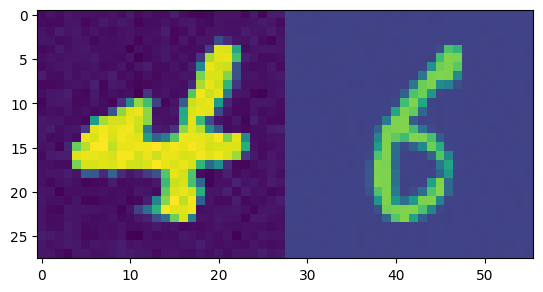

In [29]:
plt.imshow(torch.concatenate([xt[i] for i in range(xt.shape[0])][:2], dim=2).cpu()[0])

In [38]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# 1. Load Data
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)

# Get all data flattened
all_data = dataset.data.float().view(-1, 28*28).to("cuda") / 255.0
all_data = (all_data - 0.5) / 0.5 # Normalize

# 2. PCA Projection (Analytical Dimensionality Reduction)
# We calculate the Principal Components of the dataset to remove noise
# "V" contains the directions of maximum variance (the "eigen-digits")
U, S, V = torch.pca_lowrank(all_data, q=50, center=True, niter=2)
projection_matrix = V.to("cuda") # Shape: [784, 50]

def get_pca_features(x):
    # Projects images from 784 pixels down to 50 PC dimensions
    flat = x.view(x.shape[0], -1)
    return flat @ projection_matrix

# 3. Kernel Features (The "RBF" Layer)
# We pick 500 random images to serve as "Anchors" (Centers)
# This replaces the Neural Network Encoder
n_anchors = 500
perm = torch.randperm(all_data.size(0))
anchors = all_data[perm[:n_anchors]].to("cuda")
anchors_pca = get_pca_features(anchors) # Project anchors to PCA space too

gamma = 0.1 # Kernel width (tune this!)

def get_kernel_features(x_pca):
    # Computes Gaussian similarity to all 500 anchors
    # Output: [Batch, 500]
    # dist = ||x - anchor||^2
    dist_sq = torch.cdist(x_pca, anchors_pca, p=2)**2
    return torch.exp(-gamma * dist_sq)

# 4. The 1-Shot Analytical Solve (uLSIF on Kernels)
print("Solving for Theta...")

# Get "Numerator" (8s) and "Denominator" (All) features
# Note: In a real run, use a subset to save RAM if needed
target_indices = (dataset.targets == 8).nonzero(as_tuple=True)[0]
target_imgs = all_data[target_indices[:2000]]
background_imgs = all_data[:5000]

with torch.no_grad():
    phi_background = get_kernel_features(get_pca_features(background_imgs))
    phi_target = get_kernel_features(get_pca_features(target_imgs))

# H = Phi_back.T @ Phi_back
n_back = phi_background.shape[0]
H = (phi_background.T @ phi_background) / n_back
H += 0.1 * torch.eye(n_anchors).to("cuda") # Regularization

# h = mean(Phi_target)
h = torch.mean(phi_target, dim=0, keepdim=True).T

# Solve!
theta = torch.linalg.solve(H, h)
print("Theta Solved!")

Solving for Theta...
Theta Solved!


In [40]:
import torch

# Assuming 'all_data' is your normalized MNIST dataset [N, 784]
# and 'target_indices' are the indices for the digit 8

# 1. PCA Projection Matrix (Fixed features)
U, S, V = torch.pca_lowrank(all_data, q=50) # Top 50 "Eigen-digits"
proj = V.to(device)

def get_features(x):
    # x: [B, 1, 28, 28] -> [B, 50]
    x_flat = x.view(x.shape[0], -1)
    x_pca = x_flat @ proj
    
    # 2. Kernel Features (RBF)
    # Compare input to a fixed set of 'Anchor' images
    # anchors_pca: [500, 50] pre-calculated from random dataset images
    dist_sq = torch.cdist(x_pca, anchors_pca, p=2)**2
    return torch.exp(-0.1 * dist_sq) # gamma=0.1

# 3. Solve for Theta (uLSIF 1-shot)
# Done analytically as previously discussed: theta = solve(H, h)
# theta shape: [500, 1]

In [42]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from IPython.display import clear_output

# --- 1. SETUP DATA & PCA (Analytical Feature Extraction) ---
# Assuming 'train_set' is your MNIST dataset and 'model' is your unconditioned UNet
all_data = train_set.data.float().view(-1, 28*28).to(device) / 255.0
all_data = (all_data - 0.5) / 0.5  # Normalize to match diffusion range

# Analytical PCA: Find the top 50 "Eigen-digits"
U, S, V = torch.pca_lowrank(all_data, q=50)
proj = V.to(device)  # [784, 50] projection matrix

# Define anchor points for RBF Kernels (500 random images)
n_anchors = 500
perm = torch.randperm(all_data.size(0))
anchors_pca = (all_data[perm[:n_anchors]] @ proj).detach()

def get_features(x):
    """Zero-training feature extraction: Pixels -> PCA -> RBF Kernel"""
    x_flat = x.view(x.shape[0], -1)
    x_pca = x_flat @ proj
    # Gaussian Kernel Similarity: exp(-gamma * ||x - anchor||^2)
    dist_sq = torch.cdist(x_pca, anchors_pca, p=2)**2
    return torch.exp(-0.05 * dist_sq)

# --- 2. 1-SHOT ULSIF SOLVE (Analytical Theta) ---
print("Solving for Density Ratio (Theta)...")
target_label = 8
target_indices = (train_set.targets == target_label).nonzero(as_tuple=True)[0]

with torch.no_grad():
    # Background distribution (All MNIST)
    phi_de = get_features(all_data[:5000])
    # Target distribution (Digit 8)
    phi_nu = get_features(all_data[target_indices[:2000]])

# H = (1/n) * Phi^T @ Phi + lambda * I
H = (phi_de.T @ phi_de) / phi_de.shape[0]
H += 0.1 * torch.eye(n_anchors).to(device) # Regularization

# h = mean(Phi_target)
h = torch.mean(phi_nu, dim=0, keepdim=True).T

# Solve the linear system analytically
theta = torch.linalg.solve(H, h)
print("Theta solved instantly!")

# --- 3. SAMPLING LOOP WITH PCA-ULSIF GUIDANCE ---
n_samples = 10
s = 25.0  # Guidance scale
xt = torch.randn(n_samples, 1, 28, 28).to(device)



for i in reversed(range(timesteps)):
    t_tensor = torch.tensor([i] * n_samples, device=device)
    t_float = t_tensor.float() / timesteps
    
    # 1. Unconditional Score Prediction
    with torch.no_grad():
        eps_pred = model(xt, t_float)
    
    # Diffusion math constants
    a_t, ab_t, b_t = alpha[i], alpha_bar[i], beta[i]
    mean = (xt - ((1 - a_t) / torch.sqrt(1 - ab_t)) * eps_pred) / torch.sqrt(a_t)

    # 2. Direct Density Ratio Guidance (Requires Grad)
    xt_for_grad = xt.detach().requires_grad_(True)
    phi_x = get_features(xt_for_grad)
    
    # Ratio r(x) = phi(x) * theta
    ratio = phi_x @ theta
    log_r = torch.log(torch.clamp(ratio, min=1e-8))
    
    # Gradient of the log-density ratio
    guide_score = torch.autograd.grad(log_r.sum(), xt_for_grad)[0]
    
    # Apply Sugiyama's guidance to the mean
    mean = mean + s * b_t * guide_score
    
    # 3. Langevin Step
    if i > 0:
        xt = mean + torch.sqrt(b_t) * torch.randn_like(xt)
    else:
        xt = mean

    # 4. Live Progress Update
    if i % 25 == 0 or i == 0:
        clear_output(wait=True)
        fig, axes = plt.subplots(1, 10, figsize=(15, 2))
        for j in range(10):
            axes[j].imshow(xt[j, 0].detach().cpu().numpy(), cmap='gray')
            axes[j].axis('off')
        plt.suptitle(f"Timestep: {i} | Guidance: PCA + uLSIF (1-Shot)")
        plt.show()

NameError: name 'train_set' is not defined